# SIMVI on Xenium v1 — comparing spatial neighbourhood associations to SPiCe

**Environment:** `conda activate simvi_env`

This notebook runs [SIMVI](https://github.com/KlugerLab/SIMVI) (Dong et al.) on the same
Xenium v1 breast cancer dataset used for the [SPiCe](https://github.com/secrierlab/SPiCe)
analysis (`AA_00_Xenium_v1_emt_plasticity_hallmark.ipynb` /
`AA_01_Xenium_v1_emt_plasticity_hallmark.ipynb`), and asks the same biological
question SPiCe answers with its `explain_edges` / `edge_network` step: **which
spatially-neighbouring cell-type pairs are associated with each EMT state
(EPI / H-EPI / H-MES / MES)?**

SIMVI itself is unsupervised — it decomposes expression into an *intrinsic*
component (`z`, driven by the cell's own identity) and a *spatial/interaction*
component (`s`, driven by the niche), learned through a graph-attention (GAT)
encoder over the spatial k-NN graph. Neither the
[SIMVI repo](https://github.com/KlugerLab/SIMVI) nor the
[SIMVI_reproducibility](https://github.com/MingzeDong/SIMVI_reproducibility)
notebooks document a direct "cell-type-pair importance" output — the closest
tool buried in `simvi.model.SimVIModel` is `get_attention()`, which returns
the trained GAT's cell–cell attention matrix. That matrix *is* the SIMVI
analogue of SPiCe's edge-level `GNNExplainer` output: instead of asking a
supervised state-classifier which edges it leant on (SPiCe), we ask the
unsupervised spatial encoder which neighbours it attends to most when
building each cell's niche representation, and then test whether that
attention is systematically higher for particular cell-type pairs around
cells in a given EMT state (SIMVI, this notebook).

The notebook is organised as:

1. Load data & fix a normalisation gotcha specific to this file
2. Train SIMVI (intrinsic `z` / spatial `s` latents)
3. Standard SIMVI diagnostics — UMAPs, spatial-effect (SE) archetypes, gene classification
4. **Neighbourhood associations** — attention-derived cell-type-pair importance per EMT state, styled like SPiCe's `edge_network`
5. Sanity check against SPiCe's own results (already stored in this `adata`) and a model-free `squidpy` neighbourhood enrichment
6. Save results

Cell-type labels, the spatial k-NN size (`n_neighbors=12`) and the EMT state
definitions (`state_label`, quartile split of `EMT_score`) are all reused
as-is from the SPiCe run, so the two methods are compared on identical graph
structure and identical state definitions — only the interpretability method
differs.


In [1]:
import os, warnings
os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import torch
import matplotlib.pyplot as plt

FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

## 1. Load data

Same file SPiCe was run on. It already carries the SPiCe results in
`adata.uns['spice']` (from `AA_00`/`AA_01`), including `state_label`
(intended to be EMT quartile states for tumour cells only) and
`celltype_minor`.

In [2]:
DATA_PATH = (
    "/home/cenk/Withnell_spice/processed_data/xenium_v1_hallmark_simvi_results.h5ad"
)

adata = sc.read_h5ad(DATA_PATH)
adata.obs["celltype_minor"] = adata.obs["celltype_minor"].astype("category")
adata

AnnData object with n_obs × n_vars = 139320 × 313
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'dataset', 'celltype_major', 'celltype_minor', 'subclone_y', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes', 'n_counts', 'EMT_hallmarks', 'myCAF_signtaure', 'hypoxia_hallmarks', 'angio_hallmarks', 'EMT_hallmarks_alltumour', 'EMT_hallmarks_visium', 'labels', 'labels_three', 'Barcode', 'Cluster', 'EMT_score', 'tumour_cells', 'state_label', 'EMT_state', '_scvi_batch', '_scvi_labels', 'Archetype 1', 'Archetype 2', 'Archetype 3', 'Archetype 4', 'Archetype 5', 'Archetype 6', 'Archetype 7', 'celltype_or_state'
    var: 'gene_ids', 'feature_types', 'genome', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1

### A tumour-mask bug inherited from the SPiCe file

EMT plasticity states only make biological sense for tumour/cancer cells —
`AA_00_Xenium_v1_emt_plasticity_hallmark.ipynb` calls
`spice.tl.assign_state_labels(..., tumour_mask_key="tumour_cells")`
specifically to restrict labelling to tumour cells, and its docstring says
non-tumour cells (`NaN` in `tumour_mask_key`) get `state_label = -1` and are
excluded.

In this file `adata.obs["tumour_cells"]` is a fully-populated categorical
(`"tumour"` / `"non-tumour"`, no `NaN`s at all), so
`assign_state_labels`'s internal mask —
`adata.obs[tumour_mask_key].notna()` — is `True` for *every* cell. The
exclusion never fired: `state_label` was assigned to the whole 139k-cell
dataset from EMT-score quartiles computed over tumour **and** non-tumour
cells together, not tumour cells alone. You're right to flag it — and it
affects the SPiCe side too: the `node_pvalues` already stored in
`adata.uns['spice']` (from `AA_01`) were computed against this same
whole-dataset `state_label`, so if you want a strictly apples-to-apples
comparison later, SPiCe's `cross_validate`/`explain_nodes`/`explain_edges`
would need rerunning with the fix below as well.

We recompute `state_label` here the same way `assign_state_labels(n_states=4)`
does (quartile split of `EMT_score`), but with the mask it was supposed to
use: `tumour_cells == "tumour"`. Non-tumour cells get `state_label = -1` and
are excluded from every state-conditioned step below (section 4's
neighbourhood associations, the `EMT_state` UMAP colouring) — they still
remain in the spatial graph as potential *neighbours*, just not as cells
that themselves carry an EMT state.

In [3]:
EMT_MAP = {0: "EPI", 1: "H-EPI", 2: "H-MES", 3: "MES"}

tumour_mask = (adata.obs["tumour_cells"].astype(str) == "tumour").values
scores = adata.obs["EMT_score"].values.astype(float)

state_label = np.full(adata.n_obs, -1, dtype=int)
q25, q50, q75 = np.nanpercentile(scores[tumour_mask], [25, 50, 75])
tumour_scores = scores[tumour_mask]
state = np.zeros(tumour_mask.sum(), dtype=int)
state[tumour_scores > q25] = 1
state[tumour_scores > q50] = 2
state[tumour_scores > q75] = 3
state_label[tumour_mask] = state

adata.obs["state_label"] = state_label
adata.obs["EMT_state"] = adata.obs["state_label"].map(EMT_MAP).astype("category")

print(f"{tumour_mask.sum()} tumour cells assigned an EMT state; "
      f"{(~tumour_mask).sum()} non-tumour cells excluded (state_label = -1)")
print()
print(adata.obs["EMT_state"].value_counts(dropna=False))
print()
print(adata.obs["celltype_minor"].value_counts())

51584 tumour cells assigned an EMT state; 87736 non-tumour cells excluded (state_label = -1)

EMT_state
NaN      87736
EPI      12896
H-EPI    12896
H-MES    12896
MES      12896
Name: count, dtype: int64

celltype_minor
Cancer Her2 SC                 16264
Cancer LumA SC                 11992
CAFs MSC iCAF-like             11247
CAFs myCAF-like                11098
Cancer Cycling                 10750
Mature Luminal                  6969
Cancer LumB SC                  6380
Cancer Basal SC                 6198
Macrophage                      5766
T cells CD4+                    5748
Myoepithelial                   5504
Cycling T-cells                 5281
Endothelial RGS5                4276
Cycling_Myeloid                 4186
DCs                             4040
T cells CD8+                    3757
Luminal Progenitors             3652
Endothelial ACKR1               2408
Plasmablasts                    2365
Monocyte                        2238
Endothelial CXCL12              1690
NK

### A combined cell-type / EMT-state axis for the neighbourhood analysis

`celltype_minor` and `state_label` are independent axes — `celltype_minor`
keeps every tumour cell's cancer subtype (`Cancer Her2 SC`,
`Cancer Basal SC`, ...) regardless of its EMT state, and `state_label` says
nothing about non-tumour cells at all. Section 4 asks *"which cell types
neighbour cells of EMT state X"*, and we want that question to be able to
return **either** an answer like `CAFs myCAF-like` **or** an answer like
`MES` (i.e. EMT states themselves, when a state's cells are mostly
surrounded by other tumour cells sharing — or not sharing — that same
state). That second kind of answer is invisible if a tumour neighbour is
only ever identified by its cancer subtype: an actual "MES cells cluster
next to other MES cells" signal would fragment across many separate
`Cancer Her2 SC` / `Cancer Basal SC` / ... neighbour categories and wash
out, the same fragmentation problem that hid the CAF association earlier.

Note this is purely a post-hoc labelling question — SIMVI itself never
sees `celltype_minor` or `state_label` at any point; it trains
unsupervised on raw counts and the spatial graph (section 2), so nothing
about training changes here. This column only decides which labels the
*interpretation* step in section 4 is allowed to report.

`celltype_or_state` therefore relabels tumour cells by their `EMT_state`
and leaves every non-tumour cell as its normal `celltype_minor` — used as
the neighbour-identity axis for the rest of section 4, and reused as-is in
section 5b's model-free sanity check.

In [4]:
adata.obs["celltype_or_state"] = adata.obs["celltype_minor"].astype(str)
adata.obs.loc[tumour_mask, "celltype_or_state"] = adata.obs.loc[tumour_mask, "EMT_state"].astype(str)
adata.obs["celltype_or_state"] = adata.obs["celltype_or_state"].astype("category")

adata.obs["celltype_or_state"].value_counts()

celltype_or_state
EPI                            12896
MES                            12896
H-MES                          12896
H-EPI                          12896
CAFs MSC iCAF-like             11247
CAFs myCAF-like                11098
Mature Luminal                  6969
Macrophage                      5766
T cells CD4+                    5748
Myoepithelial                   5504
Cycling T-cells                 5281
Endothelial RGS5                4276
Cycling_Myeloid                 4186
DCs                             4040
T cells CD8+                    3757
Luminal Progenitors             3652
Endothelial ACKR1               2408
Plasmablasts                    2365
Monocyte                        2238
Endothelial CXCL12              1690
NK cells                        1622
NKT cells                       1588
B cells Memory                  1194
Endothelial Lymphatic LYVE1      889
PVL Differentiated               871
PVL Immature                     769
B cells Naive       

### A normalisation gotcha in this file

`adata.X` in this file is **already** `sc.pp.normalize_total` + `sc.pp.log1p`
transformed (that's what SPiCe's pipeline saved it as) — `adata.uns['log1p']`
is set and `expm1(X).sum(axis=1)` is constant (~192.5) across cells. Raw
integer counts are kept separately in `adata.layers['counts']`.

This matters because:

- **`SimVI.setup_anndata` needs raw counts** (it fits a ZINB likelihood).
  Calling it on `adata` directly (i.e. on `adata.X`) silently trains on
  already-normalised floats — `scvi-tools` only warns
  (`adata.X seems to be already log-transformed`), it doesn't error, so
  training still "runs" but the generative model is wrong. We fix this by
  pointing `setup_anndata` at `layer="counts"`, and leave `adata.X` alone.
- **`model.get_se` (spatial-effect / archetype step) wants normalised data**
  and can do the normalisation itself (`transformation="log1p"`) — but since
  `adata.X` here is already normalised, we must call it with
  `transformation="none"` instead, otherwise the data gets log1p'd twice.

## 2. Train SIMVI

`n_neighbors=12` matches SPiCe's `spice.tl.build_graph(..., n_neighbors=12)`
so both methods see the same spatial graph. Other hyperparameters follow the
defaults used in the [SIMVI_reproducibility](https://github.com/MingzeDong/SIMVI_reproducibility)
example notebooks (MERFISH/CosMx) for Xenium-scale imaging data.

On the full ~139k-cell dataset this takes roughly 1.5 hours for 100 epochs on
a single GPU.

In [5]:
from simvi.model import SimVI
from pytorch_lightning.utilities.seed import seed_everything

SimVI.setup_anndata(adata, layer="counts")
edge_index = SimVI.extract_edge_index(adata, spatial_key="spatial", n_neighbors=12)

seed_everything(0)
model = SimVI(
    adata,
    kl_weight=1,
    kl_gatweight=0.01,
    lam_mi=1000,
    permutation_rate=0.5,
    n_spatial=20,
    n_intrinsic=20,
)
train_loss, val_loss = model.train(
    edge_index, max_epochs=100, batch_size=500, use_gpu=True, mae_epochs=25
)

Global seed set to 0
Global seed set to 0
Epoch 100/100: 100%|██████████| 100/100 [1:38:00<00:00, 58.80s/it, train_loss=194, val_loss=195] 


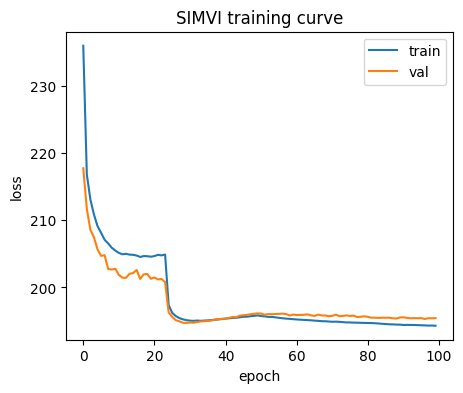

In [6]:
plt.figure(figsize=(5, 4))
plt.plot(train_loss, label="train")
plt.plot(val_loss, label="val")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.title("SIMVI training curve")
plt.show()

In [7]:
adata.obsm["simvi_z"] = model.get_latent_representation(edge_index, representation_kind="intrinsic")
adata.obsm["simvi_s"] = model.get_latent_representation(edge_index, representation_kind="interaction")
adata.obsm["simvi_all"] = model.get_latent_representation(edge_index, representation_kind="all")

## 3. Standard SIMVI diagnostics

### 3a. UMAPs of the intrinsic (`z`) vs spatial/interaction (`s`) latents

`z` should mostly separate cells by identity (cell type); `s` should mostly
reflect spatial niche / EMT state, since it is built from the GAT over
spatial neighbours.

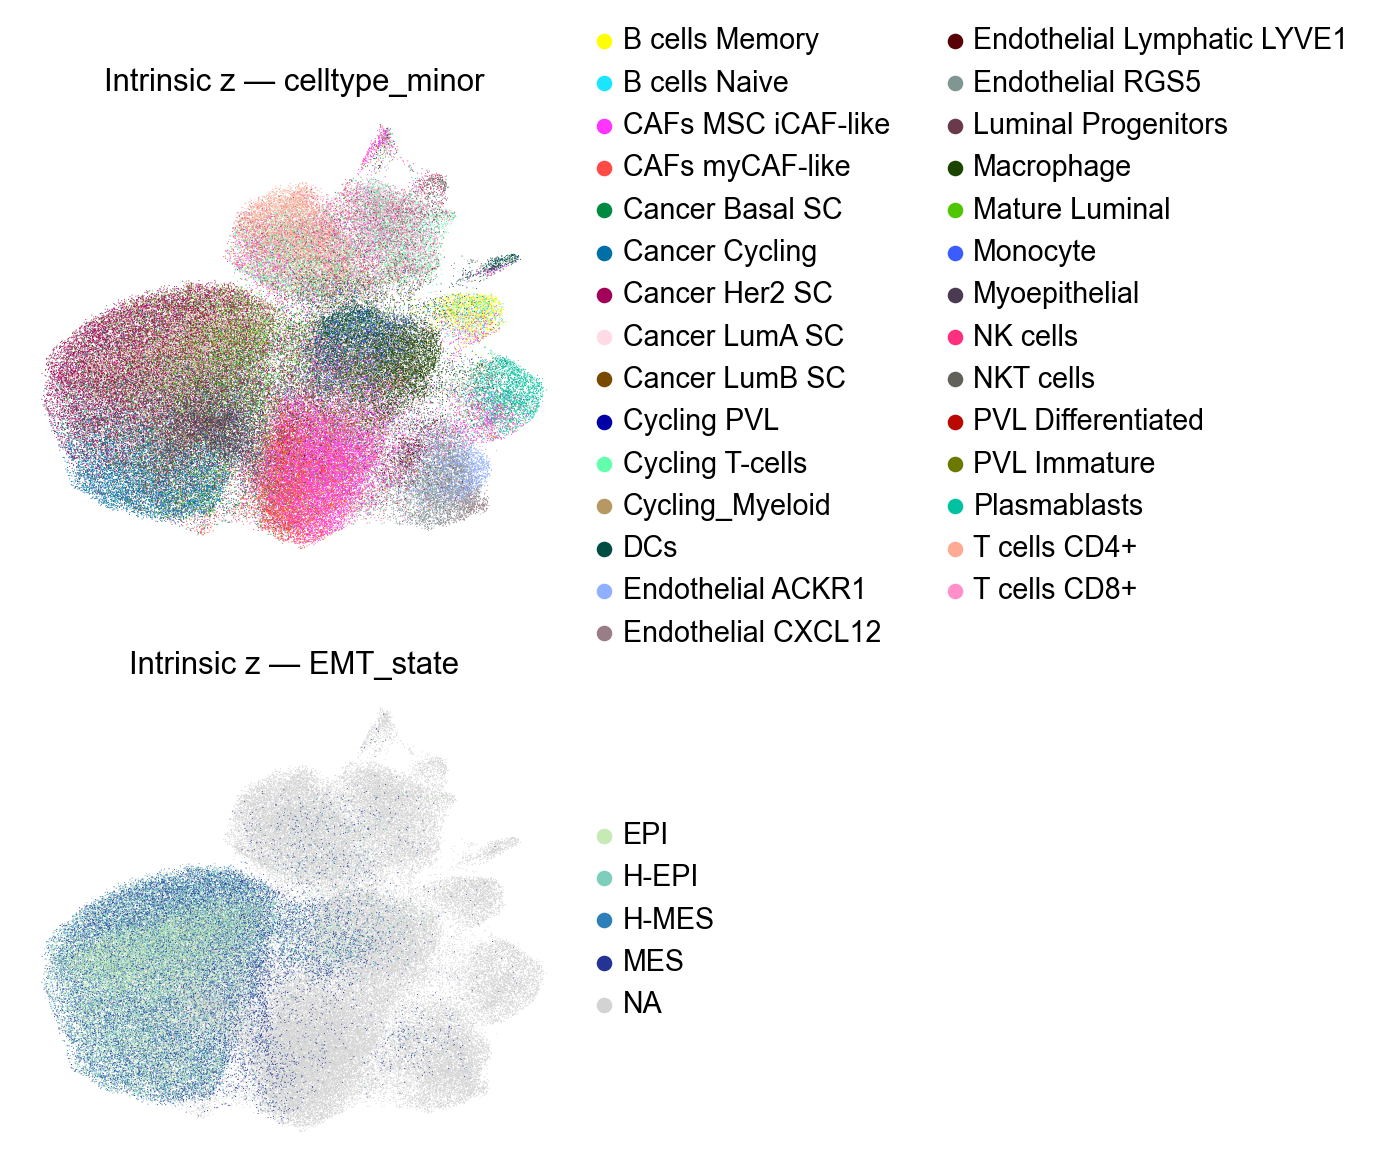

In [24]:
# adata.uns["EMT_state_colors"] = ["#c7e9b4", "#7fcdbb", "#2c7fb8", "#253494"]

# sc.pp.neighbors(adata, use_rep="simvi_z", key_added="simvi_z")
# sc.tl.umap(adata, neighbors_key="simvi_z")
# adata.obsm["X_umap_z"] = adata.obsm["X_umap"]
sc.set_figure_params(frameon=False)
sc.pl.embedding(
    adata, "X_umap_z", color=["celltype_minor", "EMT_state"],
    ncols=1, title=["Intrinsic z — celltype_minor", "Intrinsic z — EMT_state"],
    save="_simvi_z_umap.pdf"
)

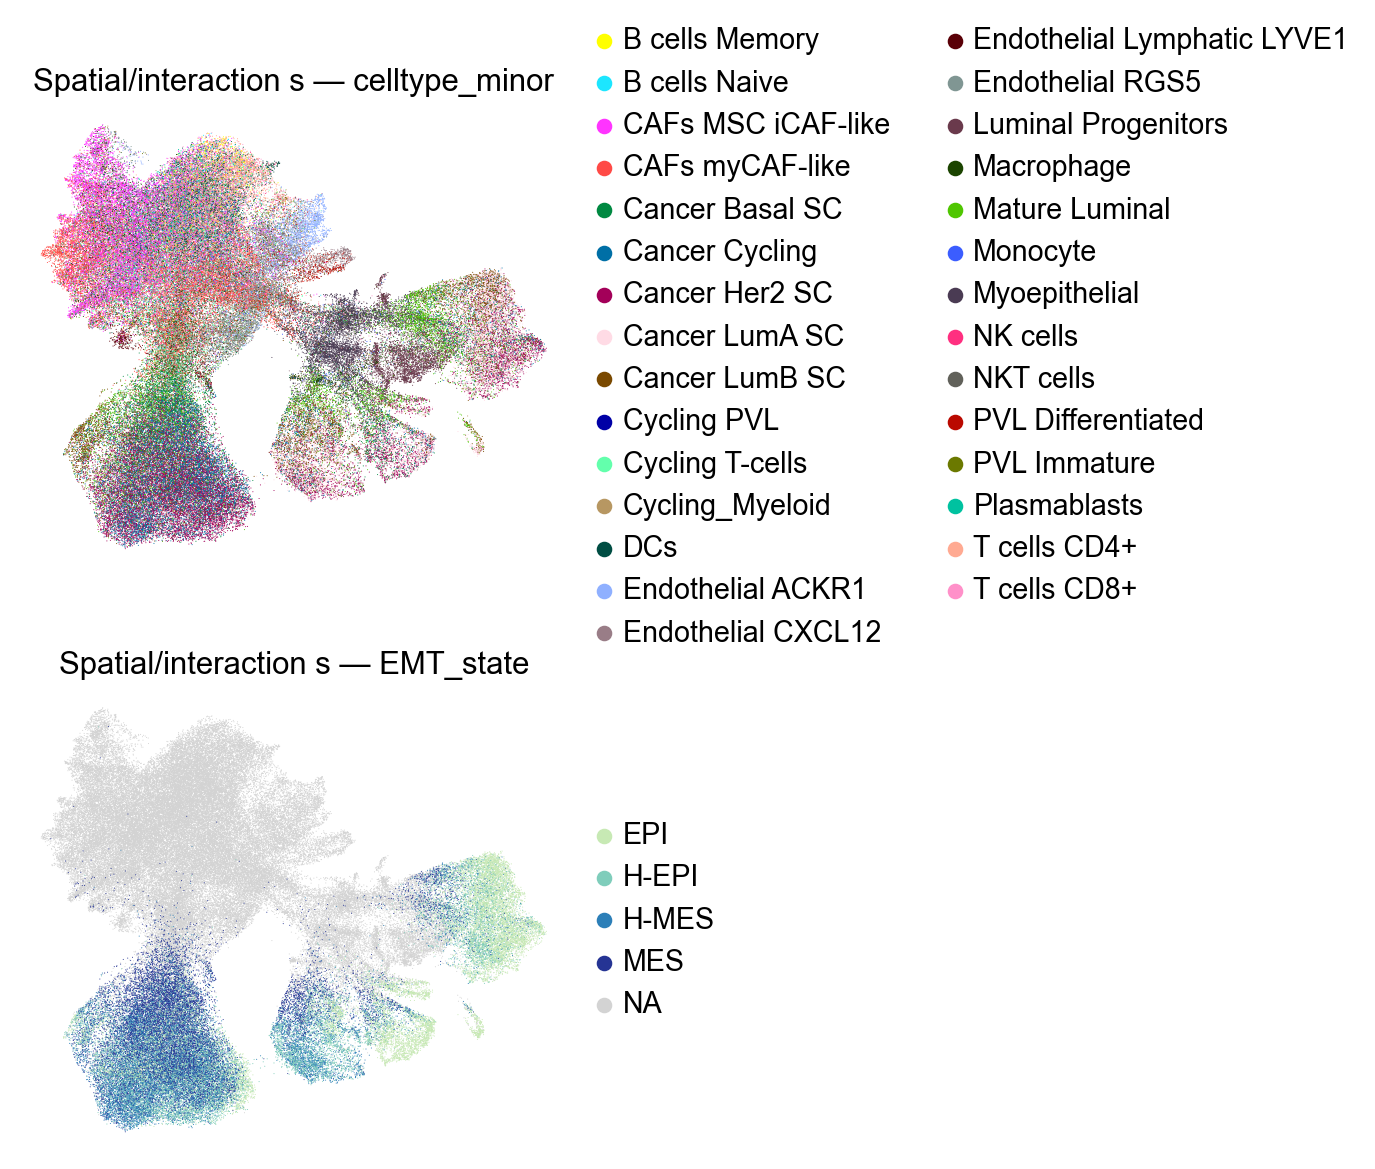

In [25]:
# sc.pp.neighbors(adata, use_rep="simvi_s", key_added="simvi_s")
# sc.tl.umap(adata, neighbors_key="simvi_s")
# adata.obsm["X_umap_s"] = adata.obsm["X_umap"]

sc.pl.embedding(
    adata, "X_umap_s", color=["celltype_minor", "EMT_state"],
    ncols=1, title=["Spatial/interaction s — celltype_minor", "Spatial/interaction s — EMT_state"],
    save="_simvi_s_umap.pdf"
)

### 3b. Spatial-effect (SE) archetype decomposition

`get_se` regresses out the intrinsic latent from each gene and from a set of
spatial-niche archetypes (double machine learning), giving an R² per gene for
how much of its variation is "intrinsic" vs "spatial/niche-induced" — SIMVI's
own gene-level readout of niche influence, complementary to the cell-type-pair
attention analysis in section 4.

`transformation="none"` because `adata.X` is already correctly normalised
(see the note above) — do **not** re-run `normalize_total`/`log1p` here.

In [10]:
import numpy as np

if not hasattr(np, "mat"):
    np.mat = np.asmatrix  # py_pcha (archetypal analysis) still references the removed np.mat alias

In [11]:
seed_everything(0)
se_list, r2_zlist, r2_slist, r2_zpvlist, r2_spvlist, S = model.get_se(
    edge_index,
    adata=adata,
    num_arch=7,
    Kfold=1,
    eps=1e-10,  # avoids a div-by-near-zero -> inf crash in the per-archetype regression;
                # the SIMVI authors' own CosMx/SlideSeqV2 notebooks set this for the same reason
    transformation="none",
    cell_type_label="celltype_minor",
)
se = np.sum(se_list, axis=0)
adata.var["r2_z"] = np.max(r2_zlist, axis=0)
adata.var["r2_s"] = np.max(r2_slist, axis=0)

Global seed set to 0


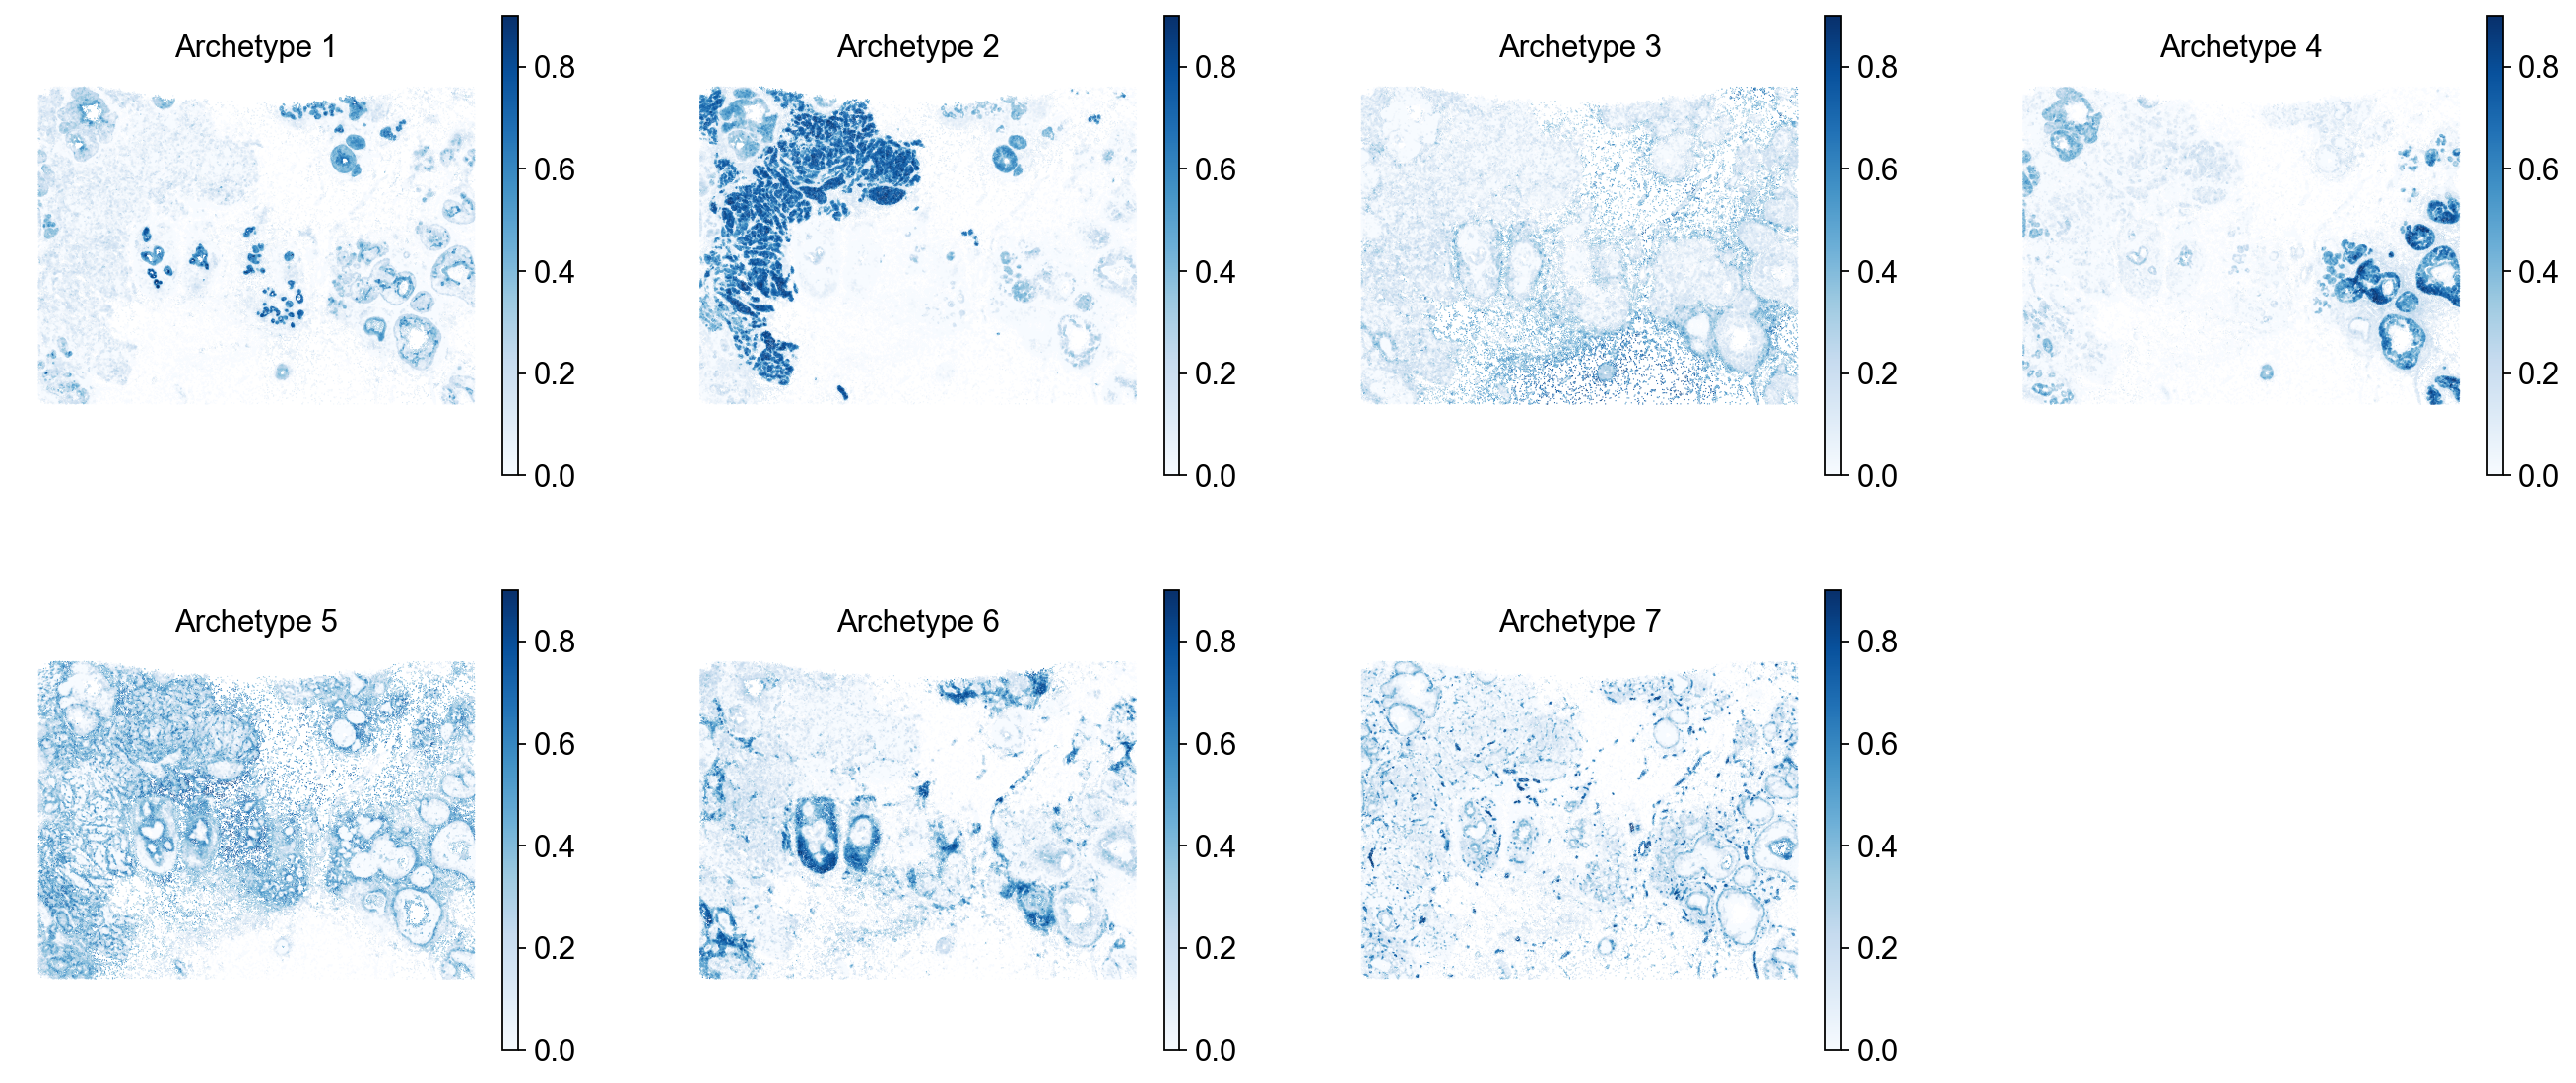

In [26]:
tt = [f"Archetype {i + 1}" for i in range(S.shape[1])]
adata.obs[tt] = S

sc.pl.spatial(
    adata, color=tt, vmax=0.9, spot_size=20, cmap="Blues", wspace=0.25, show=False,
)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, "simvi_archetype_spatial.pdf"), bbox_inches="tight")

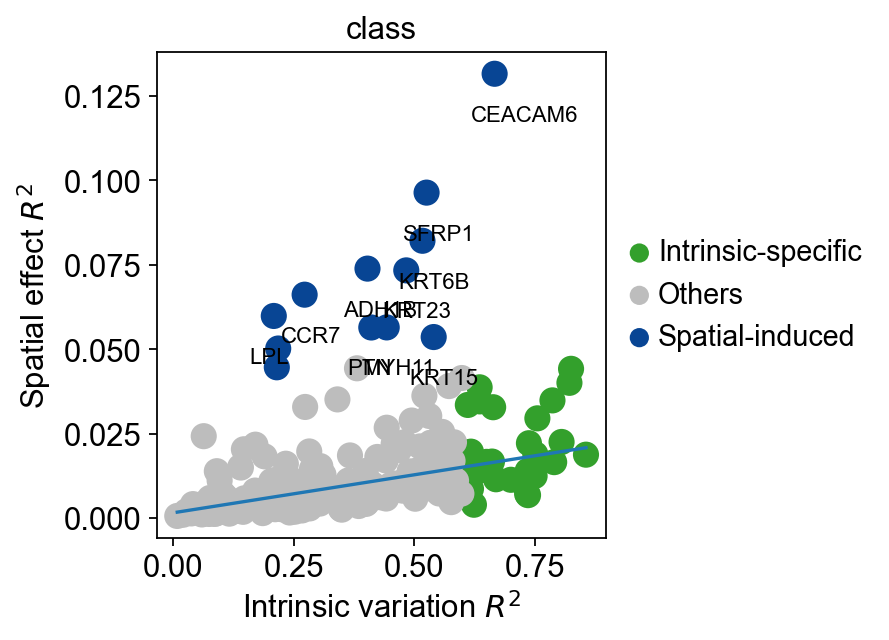

In [29]:
from sklearn.linear_model import HuberRegressor

adata_ = adata.copy()
sc.pp.highly_variable_genes(adata_, n_top_genes=300)
adata_ = adata_[:, adata_.var["means"] > 0.1].copy()

hr = HuberRegressor()
hr.fit(adata_.var["r2_z"].values.reshape(-1, 1), adata_.var["r2_s"].values)

adata_.var["class"] = "Others"
adata_.var.loc[adata_.var["r2_z"] > 0.6, "class"] = "Intrinsic-specific"
adata_.var.loc[
    np.abs(adata_.var["r2_s"].values - hr.predict(adata_.var["r2_z"].values.reshape(-1, 1)))
    / hr.scale_
    > 10,
    "class",
] = "Spatial-induced"

adata_.uns["class_colors"] = ["#33a02c", "#bdbdbd", "#084594"]

sc.pl.scatter(adata_.copy(), x="r2_z", y="r2_s", show=False, color="class")
order = np.argsort(adata_.var["r2_z"].values)
plt.plot(adata_.var["r2_z"].values[order], hr.predict(adata_.var["r2_z"].values.reshape(-1, 1))[order])
for gene, row in adata_.var.iterrows():
    if row["r2_s"] > 0.051:
        plt.text(row["r2_z"] - 0.05, row["r2_s"] - 0.014, gene, fontsize=10)

plt.xlabel("Intrinsic variation $R^2$")
plt.ylabel("Spatial effect $R^2$")
plt.tight_layout()
plt.grid(False)
plt.savefig(os.path.join(FIGURES_DIR, "simvi_r2_scatter.pdf"), bbox_inches="tight")

## 4. Neighbourhood associations (the SPiCe `edge_network` analogue)

`model.get_attention(edge_index)` returns a sparse `(n_cells, n_cells)`
matrix: row `j` holds the softmax-normalised GAT attention that cell `j`
places on each of its spatial neighbours when building its
spatial/interaction latent, so each row sums to 1.

**What we actually want to answer** is the same question SPiCe's
`edge_network` answers: *is cell type Y a significant spatial neighbour of
EMT state X?* — e.g. is `CAFs myCAF-like` associated with `EPI` or with
`MES`? That means aggregating attention by the **neighbour's** cell type
alone, per state — *not* by `(target's own cell type, neighbour's cell
type)` pairs. Pairing on the target's own type as well looks appealing
(it's what SPiCe's `cell_type_pair` does) but it fragments the signal here:
a `MES`-state cell can be any of several cancer subtypes
(`Cancer Her2 SC`, `Cancer Basal SC`, `Cancer Cycling`, ...), so a real
"CAFs are enriched around MES cells" effect gets split across many
separate `(cancer subtype, CAFs)` pairs, each individually noisier, while
`(cancer subtype A, cancer subtype B)` pairs dominate simply because
tumour nests are large and cancer cells' commonest neighbours are other
cancer cells — a density effect, not a state-specific one.

For each EMT state we:

1. sample up to `n_explanations` cells whose `state_label` equals that state
   ("target" cells), and the same number of cells sampled uniformly at
   random from all labelled (tumour) cells ("permutation" cells) —
   mirroring SPiCe's `explain_edges` target-vs-permutation design;
2. for every sampled cell, average the attention it pays to its neighbours
   *grouped by the neighbour's `celltype_or_state`* (marginalising over the
   target's own type) — non-tumour neighbours are identified by
   `celltype_minor` as normal, but tumour neighbours are identified by
   *their own* `EMT_state` rather than their cancer subtype, so a real
   `MES`-cells-cluster-near-`MES`-cells (or `EPI` near `MES`, at a
   transition zone) signal shows up as a single clean answer instead of
   fragmenting across `Cancer Her2 SC` / `Cancer Basal SC` / ... neighbour
   categories the same way the CAF signal did;
3. one-sided Welch t-test (`target > permutation`) per neighbour category,
   giving a `p_value` — a cell type (or EMT state) is called a significant
   neighbour of a state if cells in that state attend to it more than the
   tumour-wide background does.

A fine-grained, pair-resolved version keyed on `celltype_minor` on both
sides (closer to SPiCe's literal `cell_type_pair` schema, useful if you
want to know *which* cancer subtype a stromal/immune association runs
through) is kept as an appendix at the end of this section.

In [14]:
from scipy.stats import ttest_ind


def state_neighbour_associations(
    adata, attn, celltype_key="celltype_minor", state_key="state_label",
    n_explanations=300, seed=0,
):
    '''For each EMT state: which neighbouring cell types receive
    significantly more attention from that state's cells than from a
    random sample of (state-labelled) cells?'''
    celltypes = adata.obs[celltype_key].astype(str).values
    states = adata.obs[state_key].values
    rng = np.random.default_rng(seed)
    valid_idx = np.where(states >= 0)[0]

    def per_node_neighbour_means(idx_array):
        out = []
        for j in idx_array:
            row = attn.getrow(j)
            neighbours, weights = row.indices, row.data
            if len(neighbours) == 0:
                out.append({})
                continue
            d = {}
            for i, w in zip(neighbours, weights):
                d.setdefault(celltypes[i], []).append(w)
            out.append({ct: float(np.mean(v)) for ct, v in d.items()})
        return out

    results = {}
    for label_val in sorted(np.unique(states[valid_idx])):
        label_idx = valid_idx[states[valid_idx] == label_val]
        n_sample = min(n_explanations, len(label_idx))
        target_idx = rng.choice(label_idx, n_sample, replace=False)
        perm_idx = rng.choice(valid_idx, n_sample, replace=False)

        target_expl = per_node_neighbour_means(target_idx)
        perm_expl = per_node_neighbour_means(perm_idx)

        all_types = set()
        for expl in target_expl + perm_expl:
            all_types.update(expl.keys())

        records = []
        for ct in all_types:
            target_vals = [e.get(ct, 0.0) for e in target_expl]
            perm_vals = [e.get(ct, 0.0) for e in perm_expl]
            _, p = ttest_ind(target_vals, perm_vals, alternative="greater")
            records.append({
                "neighbour_celltype": ct,
                "mean_importance_target": np.mean(target_vals),
                "mean_importance_permutation": np.mean(perm_vals),
                "p_value": p,
            })
        results[label_val] = (
            pd.DataFrame(records).sort_values("p_value").reset_index(drop=True)
        )
    return results

In [15]:
attn = model.get_attention(edge_index).tocsr()

state_neighbours = state_neighbour_associations(
    adata, attn, celltype_key="celltype_or_state", state_key="state_label", n_explanations=300, seed=0,
)

for label_val, df in state_neighbours.items():
    n_sig = (df["p_value"] < 0.05).sum()
    print(f"{EMT_MAP[label_val]}: {len(df)} neighbour cell types tested, {n_sig} significant at p<0.05")

state_neighbours[0].head(10)

EPI: 26 neighbour cell types tested, 1 significant at p<0.05
H-EPI: 27 neighbour cell types tested, 1 significant at p<0.05
H-MES: 28 neighbour cell types tested, 2 significant at p<0.05
MES: 28 neighbour cell types tested, 4 significant at p<0.05


,neighbour_celltype,mean_importance_target,mean_importance_permutation,p_value
0,EPI,9.726704e-02,0.041346,2.919612e-15
1,Luminal Progenitors,5.777435e-03,0.001978,1.621903e-01
2,Macrophage,4.170617e-03,0.003613,4.497607e-01
3,H-EPI,5.064409e-02,0.060200,7.789862e-01
4,DCs,2.600896e-06,0.000027,8.187480e-01
5,Cycling_Myeloid,7.263199e-05,0.001358,8.293284e-01
6,Plasmablasts,1.307475e-08,0.000001,8.390122e-01
7,Monocyte,1.330587e-07,0.001666,8.411246e-01
8,CAFs MSC iCAF-like,7.515247e-26,0.000010,8.411425e-01
9,Endothelial ACKR1,7.698444e-26,0.000103,8.411426e-01


### Plot: which cell types are associated with each EMT state, side by side

A heatmap (rows = cell type, columns = EMT state, colour = mean attention
from that state's cells, `*` = significant vs the tumour-wide background)
is the most direct way to answer "is CAFs associated with EPI or with MES?"
— read across a row.

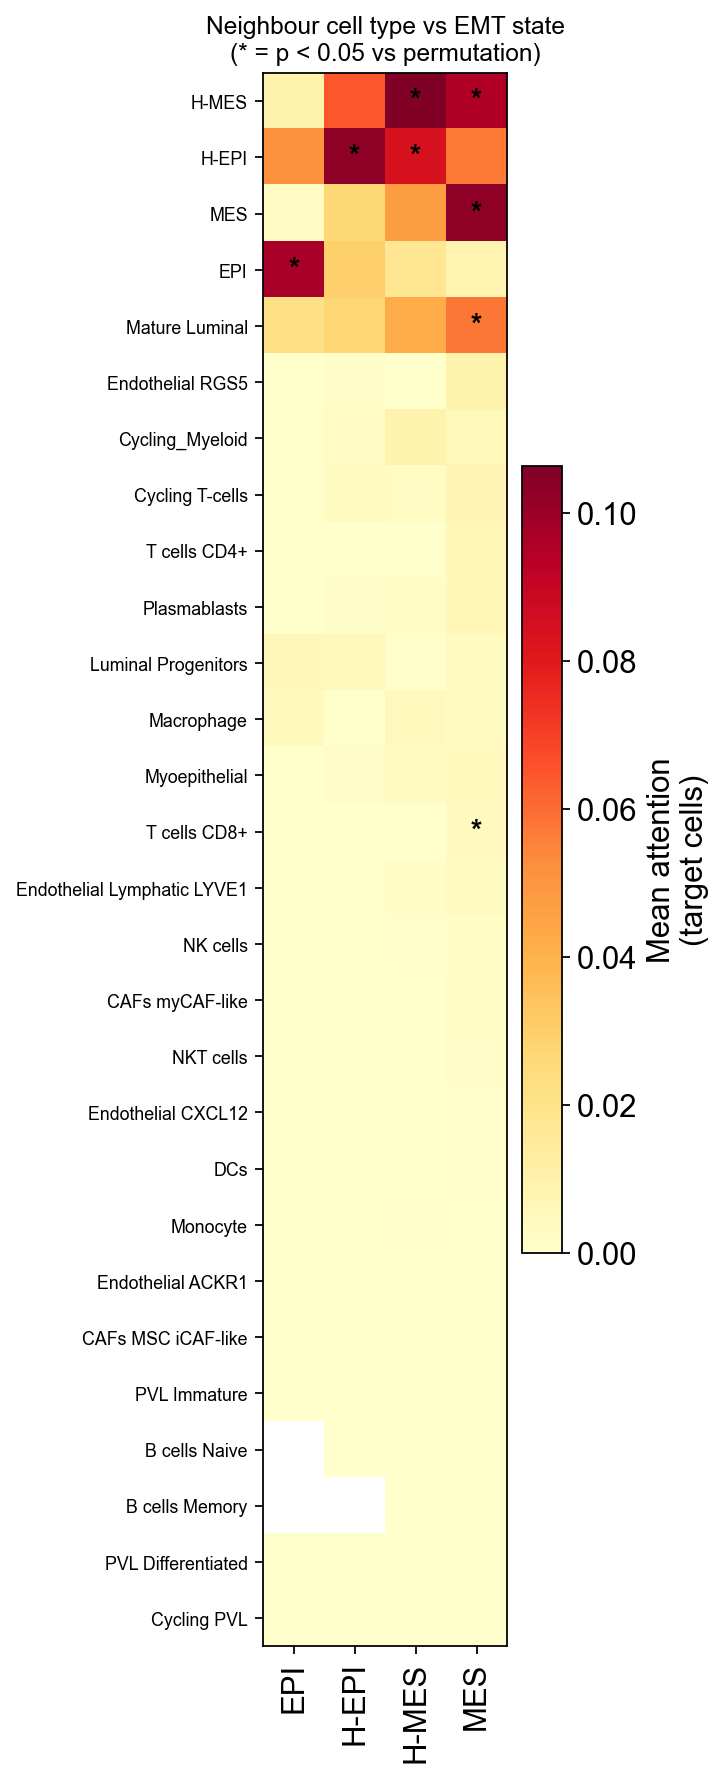

In [16]:
state_order = list(EMT_MAP.values())

heat_df = pd.concat(
    [df.assign(EMT_state=EMT_MAP[label_val]) for label_val, df in state_neighbours.items()],
    ignore_index=True,
)
importance_pivot = heat_df.pivot(index="neighbour_celltype", columns="EMT_state", values="mean_importance_target")
sig_pivot = heat_df.pivot(index="neighbour_celltype", columns="EMT_state", values="p_value") < 0.05

importance_pivot = importance_pivot[state_order]
sig_pivot = sig_pivot[state_order]
order = importance_pivot.max(axis=1).sort_values(ascending=False).index
importance_pivot, sig_pivot = importance_pivot.loc[order], sig_pivot.loc[order]

fig, ax = plt.subplots(figsize=(4.5, 0.35 * len(order) + 1.5))
im = ax.imshow(importance_pivot.values, aspect="auto", cmap="YlOrRd")
ax.set_xticks(range(len(state_order)))
ax.set_xticklabels(state_order, rotation=90)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order, fontsize=8)

for i in range(len(order)):
    for j in range(len(state_order)):
        if sig_pivot.values[i, j]:
            ax.text(j, i, "*", ha="center", va="center", color="black", fontsize=13, fontweight="bold")

fig.colorbar(im, ax=ax, shrink=0.5, label="Mean attention\n(target cells)")
ax.set_title("Neighbour cell type vs EMT state\n(* = p < 0.05 vs permutation)", fontsize=11)
fig.tight_layout()
plt.grid(False)
fig.savefig(os.path.join(FIGURES_DIR, "xenium_v1_simvi_state_neighbour_heatmap.pdf"), bbox_inches="tight", dpi=300)
plt.show()

### Plot: per-state hub-and-spoke network

Same information as the heatmap, drawn per state as a network — the state
sits at the centre, significant neighbour cell types are spokes around it,
sized/coloured by mean attention. Visually closer to SPiCe's
`edge_network` circular plots, but with the state itself (not a specific
cancer subtype) as the hub, so CAFs, immune and other cancer subtypes all
compete on equal footing as spokes.

In [17]:
import matplotlib.colors as mcolors
import matplotlib.cm as cm


def plot_state_neighbours(
    df, hub_label, alpha=0.05, min_width=0.8, max_width=6.0, figsize=(6, 6), save=None,
):
    df_sig = df[df["p_value"] < alpha].sort_values("mean_importance_target", ascending=False)
    fig, ax = plt.subplots(figsize=figsize)

    if df_sig.empty:
        ax.text(
            0.5, 0.5, f"No significant neighbour types (p < {alpha})",
            transform=ax.transAxes, ha="center", va="center", fontsize=12, color="#666666",
        )
        ax.set_title(hub_label, fontsize=14, fontweight="bold")
        ax.axis("off")
        if save:
            fig.savefig(save, bbox_inches="tight", dpi=300)
        return fig, ax

    spokes = df_sig["neighbour_celltype"].tolist()
    weights = df_sig["mean_importance_target"].values
    n = len(spokes)
    pos = {node: np.array([np.cos(2 * np.pi * k / n), np.sin(2 * np.pi * k / n)]) for k, node in enumerate(spokes)}
    hub_pos = np.array([0.0, 0.0])

    if weights.max() == weights.min():
        widths = np.full_like(weights, (min_width + max_width) / 2)
        norm = mcolors.Normalize(vmin=weights.min() - 1e-9, vmax=weights.max() + 1e-9)
    else:
        widths = min_width + (weights - weights.min()) / (weights.max() - weights.min()) * (max_width - min_width)
        norm = mcolors.Normalize(vmin=weights.min(), vmax=weights.max())
    edge_cmap = plt.get_cmap("YlOrRd")
    edge_colors = [edge_cmap(norm(w)) for w in weights]

    for node, width, color in zip(spokes, widths, edge_colors):
        ax.plot(
            [hub_pos[0], pos[node][0]], [hub_pos[1], pos[node][1]],
            linewidth=width, color=color, alpha=0.8, solid_capstyle="round", zorder=1,
        )

    ax.scatter(*hub_pos, s=2200, color="#1b1b1b", zorder=2)
    ax.text(*hub_pos, hub_label, ha="center", va="center", color="white", fontsize=11, fontweight="bold", zorder=3)
    for node in spokes:
        ax.scatter(*pos[node], s=1200, color="white", edgecolors="#1b1b1b", linewidths=2, zorder=2)
        ax.text(pos[node][0] * 1.3, pos[node][1] * 1.3, node, ha="center", va="center", fontsize=9, fontweight="bold", zorder=3)

    sm = cm.ScalarMappable(cmap=edge_cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, shrink=0.3, aspect=15, pad=0.02)
    cbar.set_label("Mean attention (target)", fontsize=10)
    cbar.outline.set_visible(False)

    ax.set_title(hub_label, fontsize=14, fontweight="bold")
    ax.set_xlim(-1.6, 1.6)
    ax.set_ylim(-1.6, 1.6)
    ax.set_aspect("equal")
    ax.axis("off")
    fig.tight_layout()
    if save:
        fig.savefig(save, bbox_inches="tight", dpi=300)
    return fig, ax

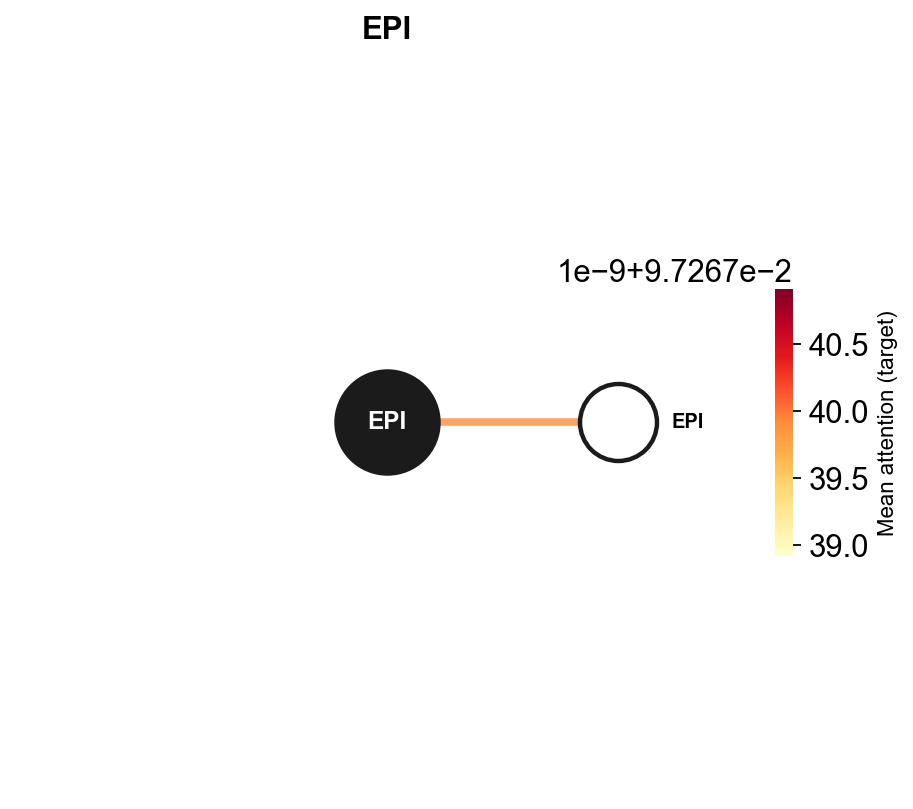

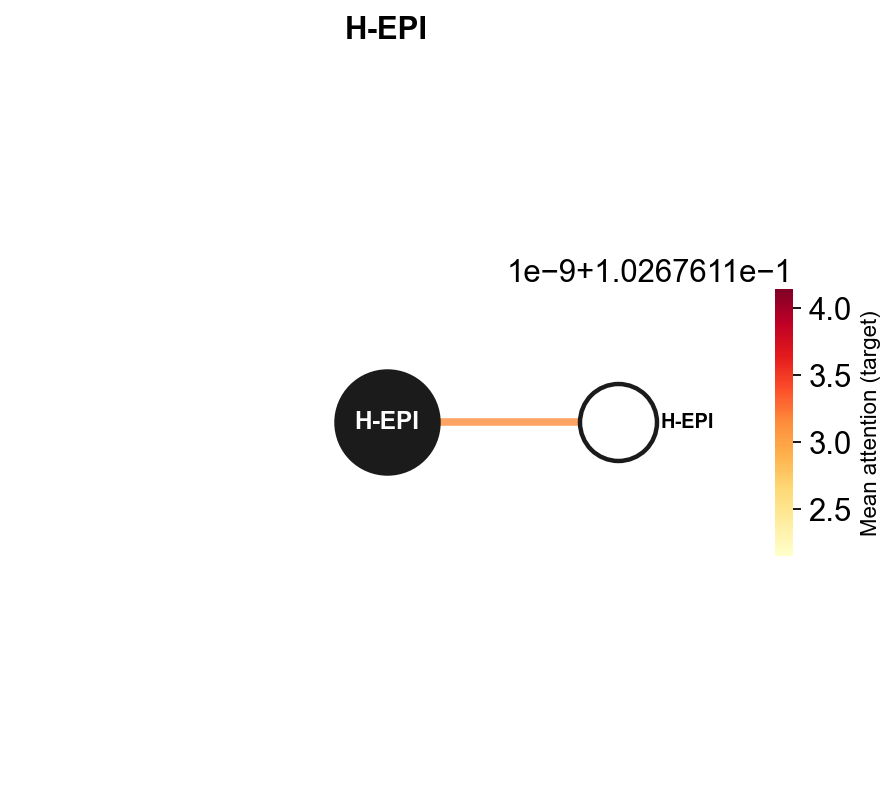

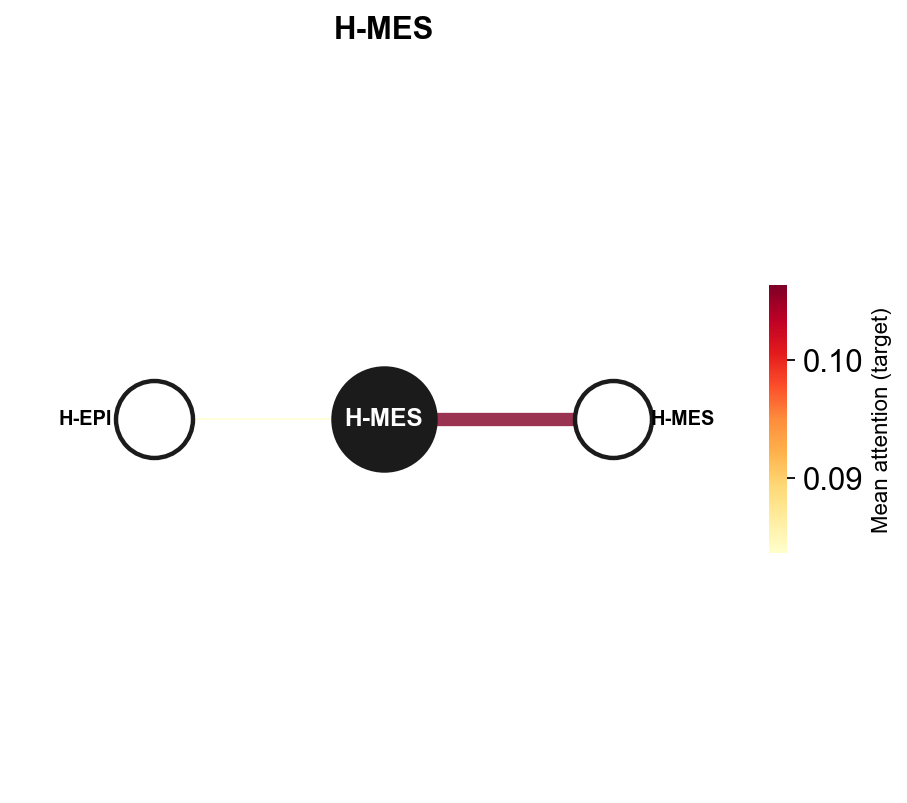

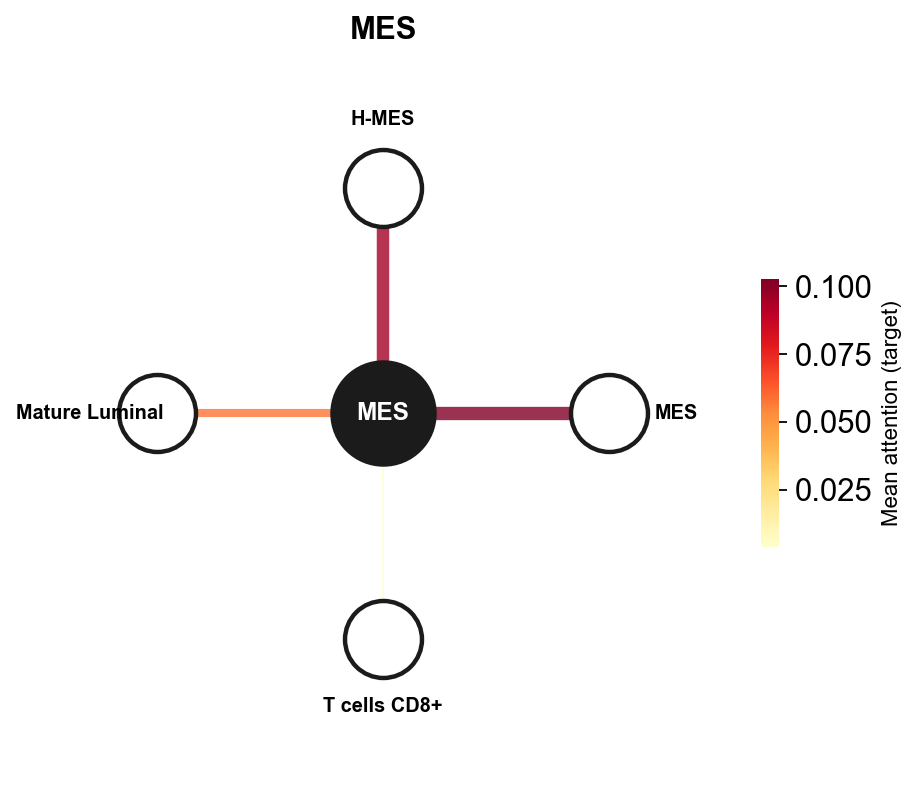

In [18]:
for label_val, df in state_neighbours.items():
    name = EMT_MAP[label_val]
    save_path = os.path.join(FIGURES_DIR, f"xenium_v1_simvi_state_neighbours_{name}.pdf")
    plot_state_neighbours(df, hub_label=name, alpha=0.05, save=save_path)
    plt.show()

### Appendix: fine-grained cancer-subtype × neighbour-type pairs

Same idea, but keeping the target cell's own `celltype_minor` as part of
the pair (like SPiCe's `cell_type_pair`) — more granular, noisier, useful
for tracing *which* cancer subtype a stromal/immune association runs
through once the heatmap above tells you it exists.

In [19]:
def edge_attention_explanations(
    adata, attn, celltype_key="celltype_minor", state_key="state_label",
    n_explanations=300, seed=0,
):
    '''Pair-resolved version of state_neighbour_associations: per-state
    (own celltype, neighbour celltype) attention importance, tested
    against a random-cell permutation null. Schema matches SPiCe's
    adata.uns['spice']['edge_explanations'].'''
    celltypes = adata.obs[celltype_key].astype(str).values
    states = adata.obs[state_key].values
    rng = np.random.default_rng(seed)
    valid_idx = np.where(states >= 0)[0]

    def per_node_pair_means(idx_array):
        out = []
        for j in idx_array:
            row = attn.getrow(j)
            neighbours, weights = row.indices, row.data
            if len(neighbours) == 0:
                out.append({})
                continue
            pairs = [tuple(sorted((celltypes[j], celltypes[i]))) for i in neighbours]
            d = {}
            for pair, w in zip(pairs, weights):
                d.setdefault(pair, []).append(w)
            out.append({pair: float(np.mean(v)) for pair, v in d.items()})
        return out

    results = {}
    for label_val in sorted(np.unique(states[valid_idx])):
        label_idx = valid_idx[states[valid_idx] == label_val]
        n_sample = min(n_explanations, len(label_idx))
        target_idx = rng.choice(label_idx, n_sample, replace=False)
        perm_idx = rng.choice(valid_idx, n_sample, replace=False)

        target_expl = per_node_pair_means(target_idx)
        perm_expl = per_node_pair_means(perm_idx)

        all_pairs = set()
        for expl in target_expl + perm_expl:
            all_pairs.update(expl.keys())

        records = []
        for pair in all_pairs:
            target_vals = [e.get(pair, 0.0) for e in target_expl]
            perm_vals = [e.get(pair, 0.0) for e in perm_expl]
            _, p = ttest_ind(target_vals, perm_vals, alternative="greater")
            records.append({
                "cell_type_pair": pair,
                "mean_importance_target": np.mean(target_vals),
                "mean_importance_permutation": np.mean(perm_vals),
                "p_value": p,
            })
        results[label_val] = (
            pd.DataFrame(records).sort_values("p_value").reset_index(drop=True)
        )
    return results


edge_explanations = edge_attention_explanations(
    adata, attn, celltype_key="celltype_minor", state_key="state_label", n_explanations=300, seed=0,
)

top_pairs = []
for label_val, df in edge_explanations.items():
    n_sig = (df["p_value"] < 0.05).sum()
    print(f"{EMT_MAP[label_val]}: {len(df)} cell-type pairs tested, {n_sig} significant at p<0.05")
    d = df[df["p_value"] < 0.05].head(10).copy()
    d.insert(0, "EMT_state", EMT_MAP[label_val])
    top_pairs.append(d)

top_pairs_df = pd.concat(top_pairs, ignore_index=True)
top_pairs_df

EPI: 105 cell-type pairs tested, 1 significant at p<0.05
H-EPI: 119 cell-type pairs tested, 0 significant at p<0.05
H-MES: 117 cell-type pairs tested, 1 significant at p<0.05
MES: 124 cell-type pairs tested, 2 significant at p<0.05


,EMT_state,cell_type_pair,mean_importance_target,mean_importance_permutation,p_value
0,EPI,"(Cancer LumA SC, Cancer LumA SC)",0.050280,0.018746,0.000007
1,H-MES,"(Cancer Her2 SC, Cancer Her2 SC)",0.034571,0.022719,0.042672
2,MES,"(Cancer Basal SC, Mature Luminal)",0.009617,0.000056,0.024803
3,MES,"(Cancer Cycling, Mature Luminal)",0.015710,0.003948,0.033436


## 5. Sanity checks

### 5a. Compare against SPiCe's own results in this `adata`

This file already carries SPiCe's node-level output
(`adata.uns['spice']['node_pvalues']`, `feature_mode="celltype"` — i.e. which
*own* cell-type identities are predictive of each EMT state). SPiCe's
edge-level output for this exact run was rendered straight to PDF rather
than saved back into the `.h5ad`
(`xenium_v1_hallmark_edge_network.pdf_*.pdf`,
`xenium_v1_hallmark_edge_importance.pdf_*.pdf`, alongside this notebook) —
open those next to the `xenium_v1_simvi_edge_network_*.pdf` files written
above for a direct visual comparison of which cell-type pairs each method
flags per state.

In [20]:
node_pvalues = adata.uns["spice"]["node_pvalues"]
node_pvalues

,B cells Memory,B cells Naive,CAFs MSC iCAF-like,CAFs myCAF-like,Cancer Basal SC,Cancer Cycling,Cancer Her2 SC,Cancer LumA SC,Cancer LumB SC,Cycling PVL,...,Mature Luminal,Monocyte,Myoepithelial,NK cells,NKT cells,PVL Differentiated,PVL Immature,Plasmablasts,T cells CD4+,T cells CD8+
0,0.397390,0.146598,9.933380e-01,7.765794e-01,9.078226e-01,9.973911e-01,1.089522e-05,4.493973e-50,2.519811e-36,0.299651,...,1.785033e-13,9.024733e-01,1.000000e+00,1.369162e-01,1.601904e-03,9.550588e-01,9.909237e-01,2.927991e-03,4.154360e-02,2.589215e-01
1,0.001144,0.017304,9.999986e-01,1.000000e+00,9.991064e-01,1.339993e-31,1.254431e-22,3.259224e-10,1.679260e-09,0.247453,...,4.997770e-20,3.176881e-03,8.429021e-01,4.200232e-10,7.198879e-09,9.998181e-01,9.999994e-01,2.128517e-08,4.631123e-11,2.842049e-02
2,0.014103,0.106476,1.000000e+00,1.000000e+00,8.088576e-04,1.533890e-03,1.539259e-03,4.520885e-01,1.793401e-02,0.912587,...,4.648614e-02,6.279359e-09,9.999982e-01,9.419380e-01,9.971817e-01,9.846979e-01,9.981068e-01,9.523485e-01,9.804217e-01,5.537590e-08
3,1.000000,0.999996,1.776391e-40,1.097035e-49,1.316490e-15,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,0.909587,...,1.000000e+00,1.000000e+00,5.437322e-17,1.000000e+00,1.000000e+00,4.574871e-23,1.007522e-18,1.000000e+00,1.000000e+00,1.000000e+00


### 5b. Model-free neighbourhood enrichment (`squidpy`)

A z-score neighbourhood enrichment computed directly from the spatial graph
and cell labels (no SIMVI or SPiCe involved) — an independent reference for
which cell types are simply spatially adjacent more often than chance.

Reuses the same `celltype_or_state` axis from section 1/4 (tumour cells
identified by `EMT_state`, non-tumour cells by `celltype_minor`), so
`CAFs myCAF-like` and `EPI`/`MES` etc. are directly comparable categories in
one enrichment matrix — the same question as section 4's heatmap, answered
by a completely different, non-model-based method. Rows/columns where
SIMVI's attention-based heatmap and this z-score agree are associations you
can trust are both spatially real *and* state-specific; where they
disagree, the attention result may be picking up something subtler than
raw adjacency (or vice versa).

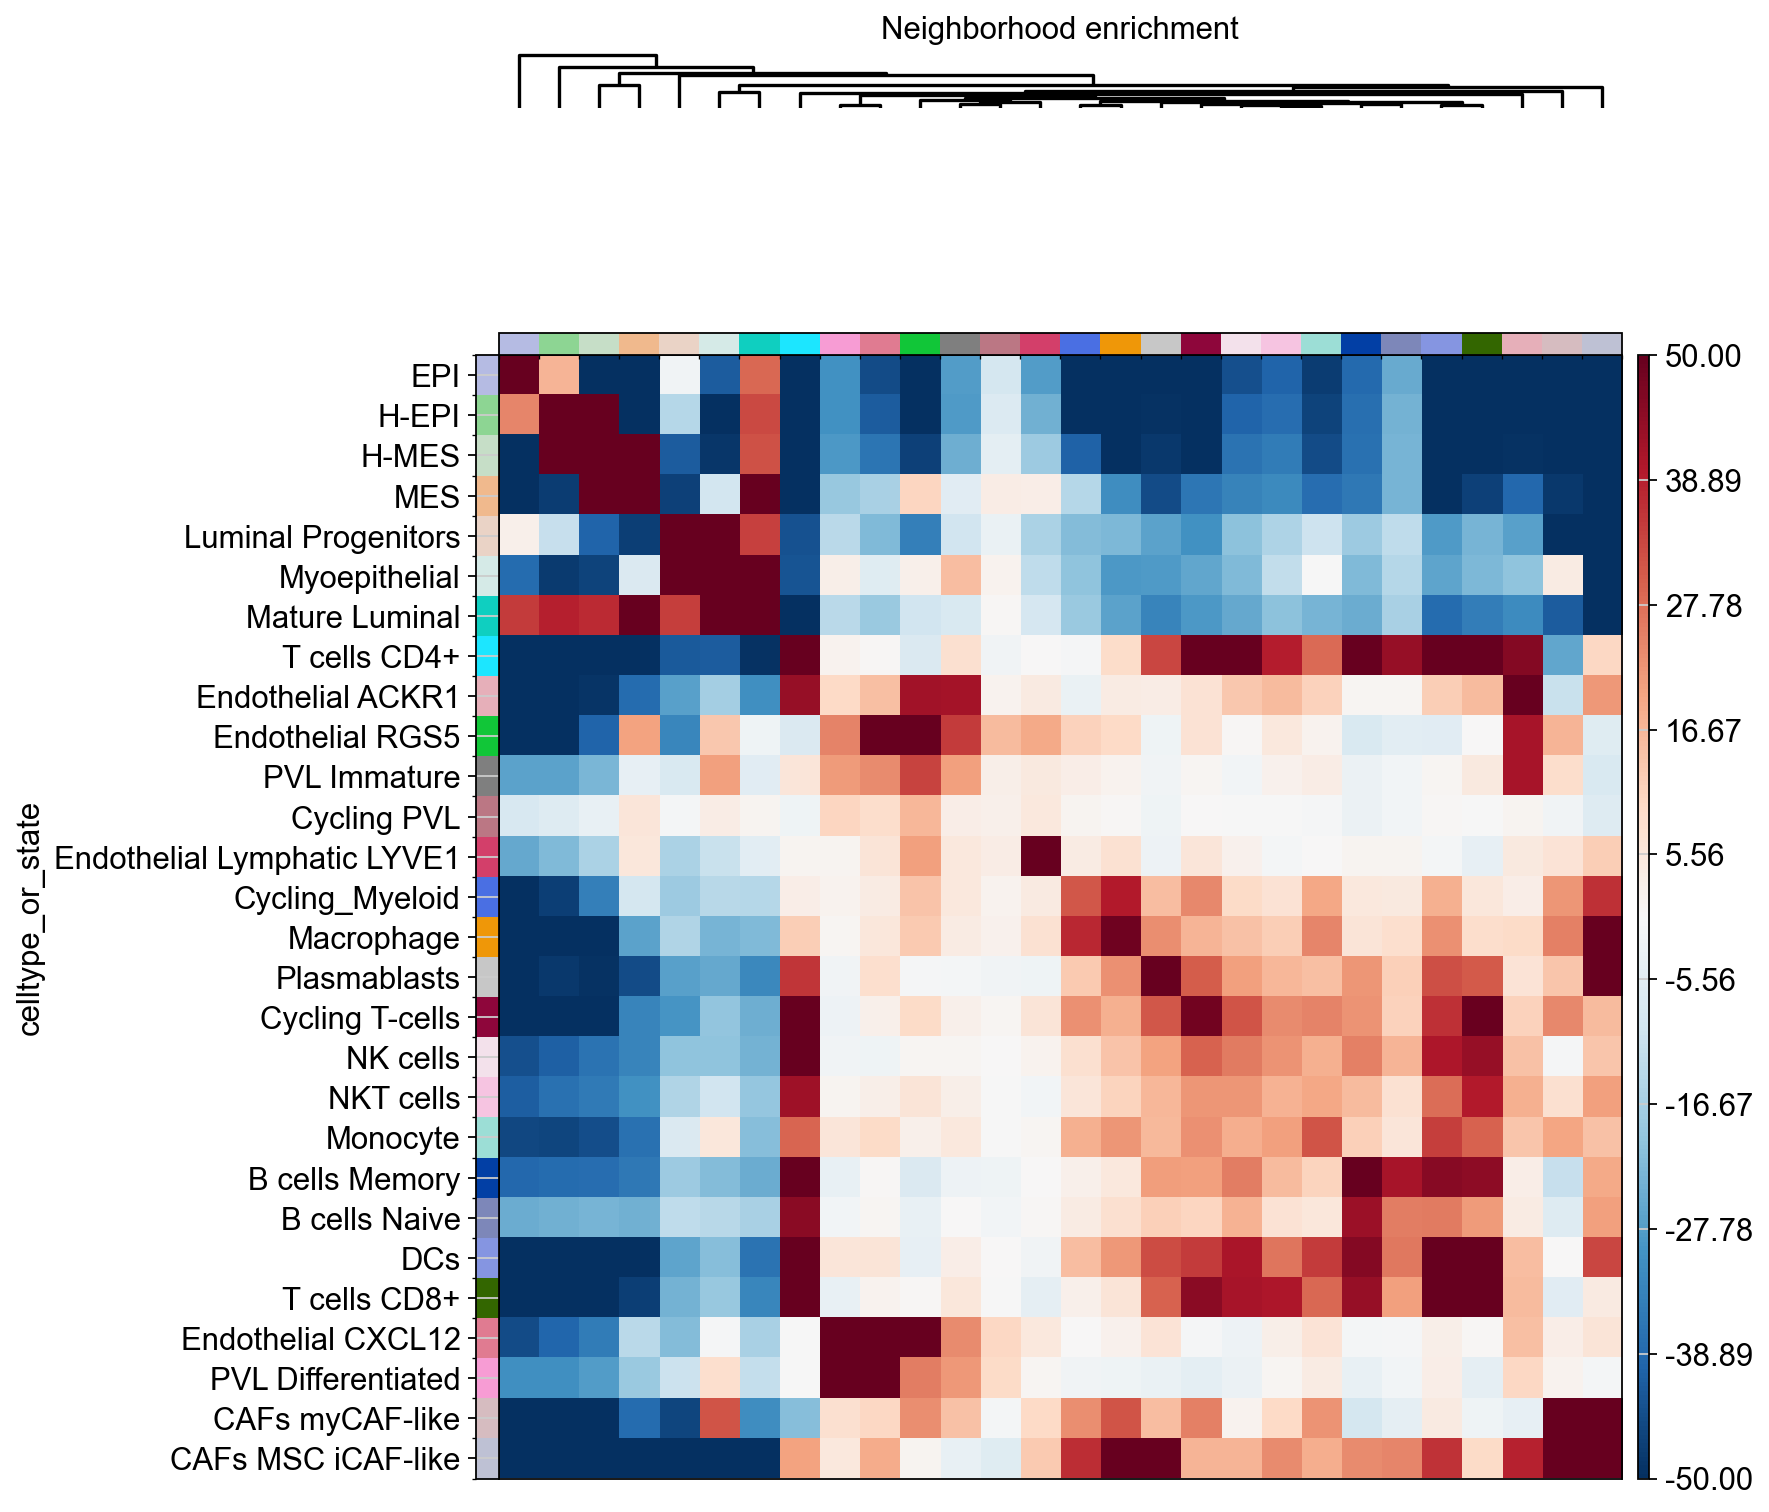

In [21]:
# sq.gr.spatial_neighbors(adata, n_neighs=12, coord_type="generic")
# sq.gr.nhood_enrichment(adata, cluster_key="celltype_or_state", seed=0)
sq.pl.nhood_enrichment(adata, cluster_key="celltype_or_state", figsize=(9, 9), cmap="RdBu_r", vcenter=0, vmin=-50, vmax=50, method="average")

## 6. Save results

CSV per state (mirrors SPiCe's own CSV-based result convention) plus a
sanitised `.h5ad` with the latents, archetype scores and gene classification
added — named to sit alongside `xenium_v1_hallmark_spice_results.h5ad`.

In [22]:
for label_val, df in state_neighbours.items():
    name = EMT_MAP[label_val]
    df.to_csv(f"simvi_state_neighbours_{name}.csv", index=False)

importance_pivot.to_csv("simvi_state_neighbour_heatmap.csv")

for label_val, df in edge_explanations.items():
    name = EMT_MAP[label_val]
    out = df.copy()
    out["cell_type_pair"] = out["cell_type_pair"].astype(str)
    out.to_csv(f"simvi_edge_explanations_pairwise_{name}.csv", index=False)

top_pairs_df.to_csv("simvi_edge_explanations_pairwise_top_pairs_all_states.csv", index=False)

In [23]:
# Persist the trained GAT's cell-cell attention matrix so downstream
# notebooks (e.g. 06_simvi_archetype_analysis.ipynb) can reuse it without retraining.
adata.obsp["simvi_attention"] = attn

adata.var["r2_z"] = adata.var["r2_z"].astype(float)
adata.var["r2_s"] = adata.var["r2_s"].astype(float)

adata.write_h5ad("processed_data/xenium_v1_hallmark_simvi_results.h5ad")